In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def step_function(x):
    if x >= 0:
        return 1
    else:
        return 0

In [3]:
class Perceptron:

    def __init__(self, input_size, learning_rate=0.1, epochs=10):
        self.weights = np.zeros(input_size + 1)
        self.lr = learning_rate
        self.epochs = epochs

    # Prediction
    def predict(self, x):
        x = np.insert(x, 0, 1)
        weighted_sum = np.dot(self.weights, x)
        return step_function(weighted_sum)

    # Training
    def train(self, X, y):
        for epoch in range(self.epochs):
            for xi, target in zip(X, y):
                xi = np.insert(xi, 0, 1)
                output = step_function(np.dot(self.weights, xi))
                error = target - output
                self.weights += self.lr * error * xi

            print(f"Epoch {epoch+1}: Weights = {self.weights}")


In [4]:
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y = np.array([0, 0, 0, 1])

print("AND Gate Input:")
print(X)

print("\nTarget Output:")
print(y)


AND Gate Input:
[[0 0]
 [0 1]
 [1 0]
 [1 1]]

Target Output:
[0 0 0 1]


In [5]:
perceptron = Perceptron(input_size=2,
                        learning_rate=0.1,
                        epochs=10)

print("\nTraining Perceptron:\n")
perceptron.train(X, y)


Training Perceptron:

Epoch 1: Weights = [0.  0.1 0.1]
Epoch 2: Weights = [-0.1  0.2  0.1]
Epoch 3: Weights = [-0.2  0.2  0.1]
Epoch 4: Weights = [-0.2  0.2  0.1]
Epoch 5: Weights = [-0.2  0.2  0.1]
Epoch 6: Weights = [-0.2  0.2  0.1]
Epoch 7: Weights = [-0.2  0.2  0.1]
Epoch 8: Weights = [-0.2  0.2  0.1]
Epoch 9: Weights = [-0.2  0.2  0.1]
Epoch 10: Weights = [-0.2  0.2  0.1]


In [6]:
print("\nAND Gate Predictions:\n")

for x in X:
    prediction = perceptron.predict(x)
    print(f"Input: {x} --> Output: {prediction}")


AND Gate Predictions:

Input: [0 0] --> Output: 0
Input: [0 1] --> Output: 0
Input: [1 0] --> Output: 0
Input: [1 1] --> Output: 1


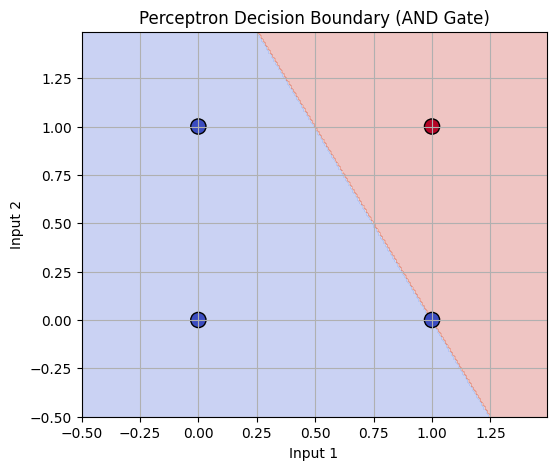

In [8]:
x_min, x_max = -0.5, 1.5
y_min, y_max = -0.5, 1.5

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.01),
    np.arange(y_min, y_max, 0.01)
)

Z = []

for point in np.c_[xx.ravel(), yy.ravel()]:
    Z.append(perceptron.predict(point))

Z = np.array(Z).reshape(xx.shape)

plt.figure(figsize=(6, 5))

plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap="coolwarm",
    edgecolors="black",
    s=120
)

plt.xlabel("Input 1")
plt.ylabel("Input 2")
plt.title("Perceptron Decision Boundary (AND Gate)")
plt.grid(True)
plt.show()